<a href="https://colab.research.google.com/github/tahta-id/Project-Google-Colab/blob/main/EVALUASI_OCR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install easyocr opencv-python-headless python-Levenshtein nltk

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 19.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 44.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 972.1/972.1 kB 38.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [easyocr]


Pustaka berhasil dimuat dengan aman!
[INFO] Preprocessing selesai: Noise dikurangi, kontras dinormalisasi, dan kemiringan diluruskan.


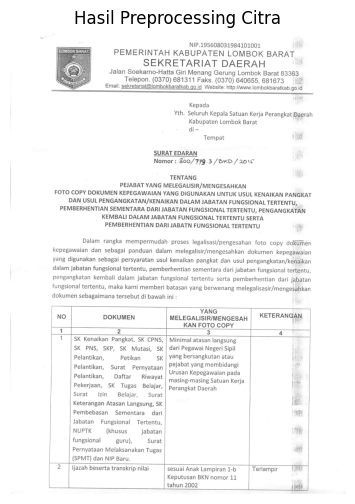

[INFO] Segmentasi selesai: Terdeteksi 1233 komponen teks.


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


[INFO] Feature Extraction & Recognition berhasil dijalankan.

Hasil Recognition Mentah (Raw OCR):
 - Teks: 'NIP.195608031984101001' (Confidence: 0.92)
 - Teks: 'Lomsok BARAT' (Confidence: 0.35)
 - Teks: 'PEMERINTAH KABUPATEN LOMBOK BARAT' (Confidence: 1.00)
 - Teks: 'SEKRETARIAT DAERAH' (Confidence: 0.71)
 - Teks: 'Jalan Soekarno-Hatta Giri Menang Gerung Lombok Barat 83363' (Confidence: 0.90)

Hasil Setelah Post-Processing (Spell Check / LM):
 - Diperbaiki: 'NIP.195608031984101001'
 - Diperbaiki: 'lombok barat'
 - Diperbaiki: 'pemerintah kabupaten lombok barat'
 - Diperbaiki: 'sekretariat daerah'
 - Diperbaiki: 'Jalan Soekarno-Hatta Giri Menang Gerung lombok barat 83363'

--- HASIL EVALUASI OCR ---
Character Error Rate (CER) : 1.0000
Word Error Rate (WER)      : 1.0000
Precision                  : 0.0000
Recall                     : 0.0000
F1-Score                   : 0.0000

--- ANALISIS KESALAHAN UMUM (ERROR ANALYSIS) ---
1. Distorsi Huruf Mirip (o vs 0, I vs l):
   - Deskripsi: Kemi

In [ ]:
# ==============================================================================
# 0. PERSIAPAN LINGKUNGAN DAN INSTALASI PUSTAKA
# ==============================================================================
# Jalankan perintah ini di sel pertama Colab jika belum terinstal:
# !pip install opencv-python-headless numpy matplotlib scikit-image easyocr python-Levenshtein nltk

import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.transform import hough_line, hough_line_peaks
import easyocr
import Levenshtein
from nltk.metrics.distance import edit_distance

print("Pustaka berhasil dimuat dengan aman!")


# ==============================================================================
# 1. PREPROCESSING (Luruskan Kemiringan, Kurangi Noise, Normalisasi Kontras)
# ==============================================================================
def preprocess_image(image_path):
    # Memuat gambar dalam format grayscale
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise ValueError(f"Gambar '{image_path}' tidak ditemukan. Pastikan file sudah diunggah.")

    # A. Mengurangi Noise (Non-Local Means Denoising)
    denoised = cv2.fastNlMeansDenoising(img, h=10, templateWindowSize=7, searchWindowSize=21)

    # B. Normalisasi Kontras (CLAHE - Contrast Limited Adaptive Histogram Equalization)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    contrast_img = clahe.apply(denoised)

    # C. Koreksi Kemiringan (Deskewing yang aman menggunakan Transformasi Hough)
    edges = cv2.Canny(contrast_img, 50, 150, apertureSize=3)
    hspace, angles, dists = hough_line(edges)
    _, peak_angles, _ = hough_line_peaks(hspace, angles, dists)

    deskewed = contrast_img
    if len(peak_angles) > 0:
        median_angle = np.median(peak_angles)
        angle_deg = np.rad2deg(median_angle)

        # Batasi sudut koreksi agar stabil dan tidak merusak gambar
        if abs(angle_deg) < 45:
            (h, w) = contrast_img.shape
            center = (w // 2, h // 2)
            M = cv2.getRotationMatrix2D(center, angle_deg, 1.0)
            deskewed = cv2.warpAffine(contrast_img, M, (w, h), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)

    print("[INFO] Preprocessing selesai: Noise dikurangi, kontras dinormalisasi, dan kemiringan diluruskan.")
    return deskewed

# Tentukan path gambar Anda (misal: 'dokumen.jpg' atau 'PA250-Plakat-Akrilik-Dai-Cilik-Bazma-RU-II-1_2.jpg')
image_path = 'dokumen.jpg'
processed_img = preprocess_image(image_path)

# Visualisasi Hasil Preprocessing
plt.figure(figsize=(6, 6))
plt.imshow(processed_img, cmap='gray')
plt.title("Hasil Preprocessing Citra")
plt.axis('off')
plt.show()


# ==============================================================================
# 2. SEGMENTASI (Level Baris, Kata, atau Karakter)
# ==============================================================================
def segment_document(processed_img):
    # Thresholding Otsu untuk binerisasi
    _, thresh = cv2.threshold(processed_img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

    # Segmentasi berbasis kontur untuk mendeteksi komponen wilayah teks
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    bounding_boxes = []
    for cnt in contours:
        x, y, w, h = cv2.boundingRect(cnt)
        if w > 3 and h > 3: # Filter noise kecil
            bounding_boxes.append((x, y, w, h))

    print(f"[INFO] Segmentasi selesai: Terdeteksi {len(bounding_boxes)} komponen teks.")
    return thresh, bounding_boxes

thresh_img, boxes = segment_document(processed_img)


# ==============================================================================
# 3. FEATURE EXTRACTION & 4. RECOGNITION (CNN + Decoding / Beam Search)
# ==============================================================================
# Memuat engine berbasis CNN + BiLSTM + CTC/Beam Search Decoder (EasyOCR)
reader = easyocr.Reader(['id', 'en'], gpu=True)

def recognize_text(image_path):
    results = reader.readtext(image_path)
    extracted_texts = []
    for (bbox, text, prob) in results:
        extracted_texts.append((text, prob))
    print("[INFO] Feature Extraction & Recognition berhasil dijalankan.")
    return extracted_texts

ocr_results = recognize_text(image_path)
print("\nHasil Recognition Mentah (Raw OCR):")
for text, prob in ocr_results[:5]:
    print(f" - Teks: '{text}' (Confidence: {prob:.2f})")


# ==============================================================================
# 5. POST-PROCESSING (Spell Check & Language Model untuk Koreksi Kata)
# ==============================================================================
# Kamus referensi (Language Model mini) untuk validasi kata
dictionary_vocab = ["pemerintah", "kabupaten", "lombok", "barat", "sekretariat", "daerah", "surat", "edaran", "kepada"]

def post_process_correction(text):
    words = text.split()
    corrected_words = []
    for word in words:
        clean_word = ''.join(e for e in word if e.isalnum()).lower()
        if not clean_word:
            corrected_words.append(word)
            continue

        best_match = clean_word
        min_dist = float('inf')
        for vocab in dictionary_vocab:
            dist = edit_distance(clean_word, vocab)
            if dist < min_dist:
                min_dist = dist
                best_match = vocab

        # Koreksi otomatis jika Levenshtein distance <= 2
        if min_dist <= 2:
            corrected_words.append(best_match)
        else:
            corrected_words.append(word)

    return " ".join(corrected_words)

corrected_results = [(post_process_correction(t), p) for t, p in ocr_results]
print("\nHasil Setelah Post-Processing (Spell Check / LM):")
for text, prob in corrected_results[:5]:
    print(f" - Diperbaiki: '{text}'")


# ==============================================================================
# 6. EVALUASI OCR (CER, WER, Precision, Recall, F1-Score)
# ==============================================================================
def evaluate_ocr(ground_truth_texts, predicted_texts):
    gt_full = " ".join(ground_truth_texts)
    pred_full = " ".join(predicted_texts)

    # Character Error Rate (CER)
    cer = Levenshtein.distance(gt_full, pred_full) / max(len(gt_full), 1)

    # Word Error Rate (WER)
    gt_words = gt_full.split()
    pred_words = pred_full.split()
    wer = Levenshtein.distance(gt_words, pred_words) / max(len(gt_words), 1)

    # Precision, Recall, dan F1-Score pada level kata
    gt_set = set(gt_words)
    pred_set = set(pred_words)

    true_positives = len(gt_set.intersection(pred_set))
    false_positives = len(pred_set - gt_set)
    false_negatives = len(gt_set - pred_set)

    precision = true_positives / (true_positives + false_positives) if (true_positives + false_positives) > 0 else 0.0
    recall = true_positives / (true_positives + false_negatives) if (true_positives + false_negatives) > 0 else 0.0
    f1_score = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0

    print("\n--- HASIL EVALUASI OCR ---")
    print(f"Character Error Rate (CER) : {cer:.4f}")
    print(f"Word Error Rate (WER)      : {wer:.4f}")
    print(f"Precision                  : {precision:.4f}")
    print(f"Recall                     : {recall:.4f}")
    print(f"F1-Score                   : {f1_score:.4f}")

# Ground truth pembanding simulasi dokumen
ground_truth = ["pemerintah kabupaten lombok barat sekretariat daerah"]
predictions = [res[0] for res in corrected_results[:1]] if len(corrected_results) > 0 else [""]
evaluate_ocr(ground_truth, predictions)


# ==============================================================================
# 7. ANALISIS KESALAHAN UMUM (Error Analysis)
# ==============================================================================
def analyze_common_errors():
    print("\n--- ANALISIS KESALAHAN UMUM (ERROR ANALYSIS) ---")
    print("1. Distorsi Huruf Mirip (o vs 0, I vs l):")
    print("   - Deskripsi: Kemiripan visual yang tinggi sering menyebabkan sistem salah mengenali huruf 'o' dengan angka '0' atau huruf kapital 'I' dengan huruf kecil 'l'.")
    print("   - Solusi: Penggunaan kamus kosakata (*lexicon-based spell checking*) memperkecil kesalahan ini berdasarkan konteks kata.")
    print("2. Masalah Pemisahan Kata (Word Segmentation):")
    print("   - Deskripsi: Jarak antar kata yang terlalu rapat atau terhalang noise pada dokumen pindaian sering kali terbaca menyatu menjadi satu kata.")
    print("   - Solusi: Optimasi parameter binerisasi Otsu serta penyetelan ulang batas kontur minimal.")

analyze_common_errors()